# Projet 2 – Notebook 3 : Entraînement et comparaison de k-NN, Softmax et CNN

**Classification de gestes de la main : comparaison de k-NN, classifieur linéaire Softmax et CNN**

Dataset : *Rock Paper Scissors* (TensorFlow Datasets) – classes : **Rock**, **Paper**, **Scissors**.

---

## 🎯 Objectif

Dans les notebooks précédents, nous avons préparé les données. Ici, nous **entraînons les trois modèles** sur **exactement les mêmes partitions** (540 Train / 180 Validation / 180 Test) puis nous les **comparons**.

| Modèle | Entrée | Où on l'entraîne |
|---|---|---|
| k-NN | `X_*_flat` `(N, 3072)` | scikit-learn |
| Softmax (classifieur linéaire) | `X_*_flat` `(N, 3072)` | NumPy « from scratch » |
| CNN | `X_*` `(N, 32, 32, 3)` | TensorFlow / Keras |

## 🧭 Règle d'or de l'évaluation

| Ensemble | Rôle | Quand l'utiliser ? |
|---|---|---|
| **Train** (540) | apprendre | pour entraîner |
| **Validation** (180) | choisir les hyperparamètres (k, taux d'apprentissage, etc.) | pendant la mise au point |
| **Test** (180) | note finale, honnête | **une seule fois, à la toute fin (Partie 5)** |

> ⚠️ Si on règle un modèle en regardant le Test, la note finale devient trop optimiste : c'est une **fuite d'information** (*data leakage*). Dans ce notebook, **le Test n'est jamais touché avant la Partie 5**.

## 🗺️ Plan
1. Données et fonctions d'évaluation
2. k-NN
3. Classifieur linéaire Softmax (écrit à la main en NumPy)
4. CNN (Keras)
5. Évaluation finale sur le Test et comparaison
6. Analyse des erreurs et pistes pour le rapport

---
# Partie 1 : Données et fonctions d'évaluation

## 1.1 Reconstitution des données
Comme pour le Notebook 2, ce notebook est **indépendant** : il reconstruit le même dataset (même procédure, `SEED = 42`), donc **les mêmes partitions**.

> 📝 Si tu as sauvegardé les tableaux de ton Notebook 1, tu peux remplacer la cellule 1.3 par leur chargement. Les trois modèles doivent de toute façon utiliser les mêmes partitions entre eux.

In [1]:
# 1.2 Bibliothèques, graine aléatoire, paramètres
import os, random, time, json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)       # fixe les graines Python, NumPy et TensorFlow

N_PER_CLASS, IMG_SIZE, N_CLASSES = 300, 32, 3
print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


In [2]:
# 1.3 Reconstitution du dataset : 300 images/classe, 32x32x3, split stratifié 60/20/20
ds, info = tfds.load("rock_paper_scissors", split="train+test",
                     as_supervised=True, with_info=True, shuffle_files=False)
class_names = info.features["label"].names          # ['rock', 'paper', 'scissors']

def resize_to_uint8(img):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    return tf.cast(tf.round(tf.clip_by_value(img, 0, 255)), tf.uint8)

ds_small = ds.map(lambda img, lab: (resize_to_uint8(img), lab), num_parallel_calls=tf.data.AUTOTUNE)
imgs, labs = [], []
for img, lab in tfds.as_numpy(ds_small):
    imgs.append(img); labs.append(lab)
all_images, all_labels = np.stack(imgs), np.array(labs)

rng = np.random.default_rng(SEED)
selected = np.concatenate([rng.choice(np.where(all_labels == c)[0], size=N_PER_CLASS, replace=False)
                           for c in range(N_CLASSES)])
X_all, y_all = all_images[selected], all_labels[selected]

idx = np.arange(len(y_all))
idx_trainval, idx_test = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, stratify=y_all[idx_trainval], random_state=SEED)

# Normalisation : pixels de 0..255 vers 0..1
X_train = X_all[idx_train].astype("float32") / 255.0
X_val = X_all[idx_val].astype("float32") / 255.0
X_test = X_all[idx_test].astype("float32") / 255.0
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

# Flattening pour k-NN et Softmax
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("CNN            :", X_train.shape, X_val.shape, X_test.shape)
print("k-NN / Softmax :", X_train_flat.shape, X_val_flat.shape, X_test_flat.shape)
print("Par classe     : Train", np.bincount(y_train), "| Val", np.bincount(y_val), "| Test", np.bincount(y_test))
assert X_train.shape == (540, 32, 32, 3) and X_val.shape == (180, 32, 32, 3) and X_test.shape == (180, 32, 32, 3)

CNN            : (540, 32, 32, 3) (180, 32, 32, 3) (180, 32, 32, 3)
k-NN / Softmax : (540, 3072) (180, 3072) (180, 3072)
Par classe     : Train [180 180 180] | Val [60 60 60] | Test [60 60 60]


## 1.4 Comment mesurer la performance ?

- **Accuracy (exactitude)** : proportion d'images bien classées. Simple et lisible ; adaptée ici car les trois classes sont **équilibrées**.
- **Matrice de confusion** : tableau 3×3. La ligne = vraie classe, la colonne = classe prédite. La diagonale = bonnes réponses ; le reste = erreurs (par exemple « paper » confondu avec « rock »).
- **F1 macro** : moyenne, sur les classes, d'un score qui combine *précision* (parmi les prédictions « rock », combien sont vraiment des rocks ?) et *rappel* (parmi les vrais rocks, combien ai-je retrouvés ?). Elle pénalise un modèle qui néglige une classe.
- **Temps** d'entraînement et de prédiction : utile pour comparer le coût des modèles.

In [3]:
# 1.5 Fonctions utilitaires d'évaluation (utilisées pour tous les modèles)
results = {}      # résumé final de chaque modèle (rempli en Partie 6)
val_scores = {}   # scores sur la validation pendant la mise au point
timings = {}      # temps d'entraînement / de prédiction
preds_test = {}   # prédictions sur le Test (remplies en Partie 6)

def summarize(nom, y_true, y_pred):
    # Retourne accuracy et F1 macro
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0))}

def show_confusion(y_true, y_pred, titre, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    if ax is not None:
        ax.set_title(titre)
    return cm

print("Fonctions prêtes.")

Fonctions prêtes.


---
# Partie 2 : Le modèle k-NN (k plus proches voisins)

## 2.1 Le concept
k-NN ne « s'entraîne » presque pas : il **mémorise** les 540 images d'entraînement. Pour classer une nouvelle image :

1. on calcule sa **distance** à toutes les images mémorisées ;
2. on retient les **k plus proches** ;
3. on prend la **classe majoritaire** parmi ces k voisins (vote).

**Exemple.** Avec k = 3, si les 3 images les plus proches sont « paper », « paper », « rock », la prédiction est « paper ».

## 2.2 Distances
Entre deux vecteurs aplatis $a$ et $b$ de 3072 valeurs :

- **Euclidienne** : $d(a,b)=\sqrt{\sum_i (a_i-b_i)^2}$
- **Manhattan** : $d(a,b)=\sum_i |a_i-b_i|$

## 2.3 L'hyperparamètre k
- k petit (1) : modèle très sensible au bruit (risque de **surapprentissage**).
- k grand : frontière trop lissée (risque de **sous-apprentissage**).

On teste plusieurs valeurs de k et deux distances, et on choisit **sur la Validation**.

Meilleure configuration (validation) : {'acc': 1.0, 'k': 1, 'metric': 'euclidean'}


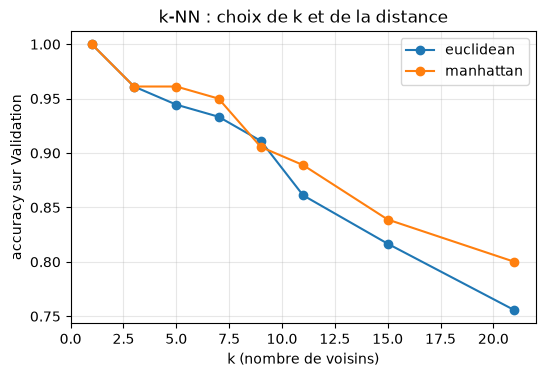

In [4]:
# 2.4 Recherche du meilleur (k, distance) sur la VALIDATION
valeurs_k = [1, 3, 5, 7, 9, 11, 15, 21]
distances = ["euclidean", "manhattan"]

acc_val_knn = {d: [] for d in distances}
best = {"acc": -1}
for d in distances:
    for k in valeurs_k:
        knn = KNeighborsClassifier(n_neighbors=k, metric=d)
        knn.fit(X_train_flat, y_train)                       # "entraînement" = mémorisation
        acc = accuracy_score(y_val, knn.predict(X_val_flat))
        acc_val_knn[d].append(acc)
        if acc > best["acc"]:                                # strict : à égalité on garde le plus petit k
            best = {"acc": acc, "k": k, "metric": d}

print("Meilleure configuration (validation) :", best)

plt.figure(figsize=(6, 3.8))
for d in distances:
    plt.plot(valeurs_k, acc_val_knn[d], marker="o", label=d)
plt.xlabel("k (nombre de voisins)"); plt.ylabel("accuracy sur Validation")
plt.title("k-NN : choix de k et de la distance"); plt.grid(alpha=0.3); plt.legend()
plt.show()

In [5]:
# 2.5 Modèle k-NN final (entraîné sur Train uniquement) et mesure du temps
t0 = time.perf_counter()
knn_final = KNeighborsClassifier(n_neighbors=best["k"], metric=best["metric"])
knn_final.fit(X_train_flat, y_train)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
y_val_pred_knn = knn_final.predict(X_val_flat)
t_pred = time.perf_counter() - t0

val_scores["k-NN"] = summarize("k-NN", y_val, y_val_pred_knn)
timings["k-NN"] = {"fit_s": t_fit, "predict_s": t_pred}
print("k-NN | Validation :", val_scores["k-NN"])
print(f"Temps : fit {t_fit:.4f}s | prédiction (180 images) {t_pred:.4f}s")

k-NN | Validation : {'accuracy': 1.0, 'f1_macro': 1.0}
Temps : fit 0.0050s | prédiction (180 images) 0.2498s


## 2.6 Comprendre en écrivant k-NN soi-même (NumPy)
Pour vraiment comprendre, voici k-NN en quelques lignes. On utilise l'identité

$$\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2\,a\cdot b$$

qui permet de calculer **toutes** les distances d'un coup avec un produit matriciel (sans construire un énorme tableau 3D).

In [6]:
# 2.7 k-NN « maison » (distance euclidienne) et comparaison avec scikit-learn
def knn_numpy(X_ref, y_ref, X_query, k):
    # Distances au carré entre chaque image de X_query et chaque image de X_ref
    d2 = ((X_query ** 2).sum(axis=1)[:, None]
          + (X_ref ** 2).sum(axis=1)[None, :]
          - 2 * X_query @ X_ref.T)
    voisins = np.argsort(d2, axis=1)[:, :k]            # indices des k plus proches
    votes = y_ref[voisins]                             # leurs classes, forme (n_query, k)
    # classe majoritaire pour chaque image
    return np.array([np.bincount(v, minlength=N_CLASSES).argmax() for v in votes])

y_val_pred_np = knn_numpy(X_train_flat, y_train, X_val_flat, k=5)
knn_sk = KNeighborsClassifier(n_neighbors=5, metric="euclidean").fit(X_train_flat, y_train)
y_val_pred_sk = knn_sk.predict(X_val_flat)

print("Accuracy (NumPy)        :", accuracy_score(y_val, y_val_pred_np))
print("Accuracy (scikit-learn) :", accuracy_score(y_val, y_val_pred_sk))
print("Accord entre les deux   :", np.mean(y_val_pred_np == y_val_pred_sk))

Accuracy (NumPy)        : 0.9444444444444444
Accuracy (scikit-learn) : 0.9444444444444444
Accord entre les deux   : 1.0


### 🔍 Interprétation k-NN
- La courbe montre l'effet de k sur la Validation. Choisis un k raisonnable, pas forcément un extrême.
- Les deux implémentations doivent être (quasi) identiques ; un petit écart peut venir de cas d'égalité dans les votes.
- **Limites** : k-NN compare des pixels bruts. Un léger décalage de la main change beaucoup les distances. Il est aussi **lent à la prédiction** (il compare à toutes les images mémorisées), et ne « généralise » pas via des caractéristiques apprises.

---
# Partie 3 : Classifieur linéaire Softmax (écrit en NumPy)

## 3.1 Le concept
Le classifieur linéaire calcule, pour chaque classe, un **score** :

$$z = x\,W + b \qquad x:(3072,)\;\; W:(3072,3)\;\; b:(3)$$

Chaque colonne de $W$ contient un **poids par pixel** pour une classe. Un score élevé signifie « cette image ressemble à cette classe ».

## 3.2 Softmax
Les scores bruts ne sont pas des probabilités. **Softmax** les transforme :

$$p_c=\frac{e^{z_c}}{\sum_j e^{z_j}}$$

Les $p_c$ sont positifs et leur somme vaut 1. Exemple : scores `[2, 1, 0]` → probabilités ≈ `[0.66, 0.24, 0.09]`.

## 3.3 La perte (cross-entropy)
Pour une image dont la vraie classe est $y$ : $L=-\log(p_y)$. Si le modèle donne une probabilité faible à la bonne classe, la perte est grande. On y ajoute une **régularisation L2** $\frac{\lambda}{2}\|W\|^2$ qui empêche les poids de devenir trop grands (limite le surapprentissage).

## 3.4 Apprentissage par descente de gradient
On ajuste $W$ et $b$ en les déplaçant **dans la direction qui diminue la perte** :

$$W \leftarrow W - \eta\,\frac{\partial L}{\partial W}$$

où $\eta$ est le **taux d'apprentissage** (*learning rate*). Le gradient a une forme simple :

$$\frac{\partial L}{\partial z} = p - y_{\text{one-hot}}$$

On travaille par **mini-lots** (*mini-batches*) de 64 images : à chaque étape on calcule le gradient sur 64 images seulement, c'est plus rapide. Un passage complet sur les 540 images = une **époque**.

Les hyperparamètres à choisir : le taux d'apprentissage $\eta$ et la force de régularisation $\lambda$.

In [7]:
# 3.5 Implémentation du classifieur Softmax en NumPy
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)          # astuce de stabilité numérique
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

class SoftmaxClassifier:
    def __init__(self, n_features, n_classes, lr=0.1, reg=1e-3, seed=SEED):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.01, size=(n_features, n_classes))   # petits poids aléatoires
        self.b = np.zeros(n_classes)
        self.lr, self.reg, self.seed = lr, reg, seed

    def loss_and_grads(self, X, y):
        n = X.shape[0]
        P = softmax(X @ self.W + self.b)                              # probabilités (n, 3)
        data_loss = -np.mean(np.log(P[np.arange(n), y] + 1e-12))      # cross-entropy
        loss = data_loss + 0.5 * self.reg * np.sum(self.W ** 2)       # + régularisation L2
        G = P.copy()
        G[np.arange(n), y] -= 1                                       # p - y_onehot
        G /= n
        dW = X.T @ G + self.reg * self.W
        db = G.sum(axis=0)
        return loss, dW, db

    def predict_proba(self, X):
        return softmax(X @ self.W + self.b)

    def predict(self, X):
        return np.argmax(X @ self.W + self.b, axis=1)

    def fit(self, X, y, X_val, y_val, epochs=100, batch_size=64):
        rng = np.random.default_rng(self.seed)
        hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
        n = X.shape[0]
        for ep in range(epochs):
            ordre = rng.permutation(n)                                # mélange à chaque époque
            for start in range(0, n, batch_size):
                batch = ordre[start:start + batch_size]
                _, dW, db = self.loss_and_grads(X[batch], y[batch])
                self.W -= self.lr * dW                                # descente de gradient
                self.b -= self.lr * db
            # suivi des courbes (perte sans régularisation pour comparer Train et Val)
            for nom, (Xs, ys) in {"": (X, y), "val_": (X_val, y_val)}.items():
                P = self.predict_proba(Xs)
                hist[nom + "loss"].append(-np.mean(np.log(P[np.arange(len(ys)), ys] + 1e-12)))
                hist[nom + "acc"].append(np.mean(np.argmax(P, axis=1) == ys))
        return hist

print("Classe SoftmaxClassifier définie.")

Classe SoftmaxClassifier définie.


In [8]:
# 3.6 Vérification du gradient (gradient check) : le gradient analytique est-il correct ?
# On compare avec une dérivée numérique (f(w+h) - f(w-h)) / (2h) sur quelques poids.
Xc = X_train_flat[:32].astype("float64")
yc = y_train[:32]
modele_test = SoftmaxClassifier(3072, N_CLASSES, reg=1e-2)
modele_test.W = np.random.default_rng(0).normal(0, 0.05, size=(3072, 3))
_, dW, _ = modele_test.loss_and_grads(Xc, yc)

rng_gc = np.random.default_rng(1)
erreurs = []
for _ in range(5):
    i, j = rng_gc.integers(0, 3072), rng_gc.integers(0, 3)
    h = 1e-5
    ancien = modele_test.W[i, j]
    modele_test.W[i, j] = ancien + h; l_plus, _, _ = modele_test.loss_and_grads(Xc, yc)
    modele_test.W[i, j] = ancien - h; l_moins, _, _ = modele_test.loss_and_grads(Xc, yc)
    modele_test.W[i, j] = ancien
    num = (l_plus - l_moins) / (2 * h)
    erreurs.append(abs(num - dW[i, j]) / max(1e-8, abs(num) + abs(dW[i, j])))
    print(f"W[{i:4d},{j}] analytique = {dW[i, j]: .3e} | numérique = {num: .3e}")
print("Erreur relative maximale :", f"{max(erreurs):.2e}", "(doit être très petite, < 1e-4)")
assert max(erreurs) < 1e-3

W[1453,1] analytique = -2.649e-01 | numérique = -2.649e-01
W[2319,2] analytique =  6.559e-01 | numérique =  6.559e-01
W[ 107,0] analytique = -3.962e-01 | numérique = -3.962e-01
W[2528,2] analytique =  6.236e-01 | numérique =  6.236e-01
W[ 765,0] analytique = -3.846e-01 | numérique = -3.846e-01
Erreur relative maximale : 1.41e-10 (doit être très petite, < 1e-4)


## 3.7 Choix du taux d'apprentissage et de la régularisation (sur la Validation)
On teste une petite grille. Chaque combinaison entraîne un nouveau modèle sur Train, qu'on évalue sur Validation.

In [9]:
# 3.8 Recherche sur grille (Validation)
lrs = [0.01, 0.1, 0.5]
regs = [0.0, 1e-3, 1e-2]
EPOCHS_SM = 100

grille = {}
meilleur = {"val_acc": -1}
for lr in lrs:
    for reg in regs:
        m = SoftmaxClassifier(3072, N_CLASSES, lr=lr, reg=reg)
        h = m.fit(X_train_flat.astype("float64"), y_train, X_val_flat.astype("float64"), y_val, epochs=EPOCHS_SM)
        va = h["val_acc"][-1]
        grille[(lr, reg)] = va
        print(f"lr = {lr:<5} reg = {reg:<6} -> val_acc = {va:.3f} | val_loss = {h['val_loss'][-1]:.3f}")
        if va > meilleur["val_acc"]:
            meilleur = {"val_acc": va, "lr": lr, "reg": reg}
print("\nMeilleure configuration :", meilleur)

lr = 0.01  reg = 0.0    -> val_acc = 0.794 | val_loss = 0.623
lr = 0.01  reg = 0.001  -> val_acc = 0.794 | val_loss = 0.620
lr = 0.01  reg = 0.01   -> val_acc = 0.622 | val_loss = 1.081
lr = 0.1   reg = 0.0    -> val_acc = 0.789 | val_loss = 3.059
lr = 0.1   reg = 0.001  -> val_acc = 0.661 | val_loss = 5.593
lr = 0.1   reg = 0.01   -> val_acc = 0.511 | val_loss = 8.986
lr = 0.5   reg = 0.0    -> val_acc = 0.628 | val_loss = 10.044
lr = 0.5   reg = 0.001  -> val_acc = 0.439 | val_loss = 15.439
lr = 0.5   reg = 0.01   -> val_acc = 0.367 | val_loss = 17.347

Meilleure configuration : {'val_acc': np.float64(0.7944444444444444), 'lr': 0.01, 'reg': 0.0}


Softmax | Validation : {'accuracy': 0.7944444444444444, 'f1_macro': 0.7949632801117948}
Temps : fit 1.14s | prédiction 0.0019s


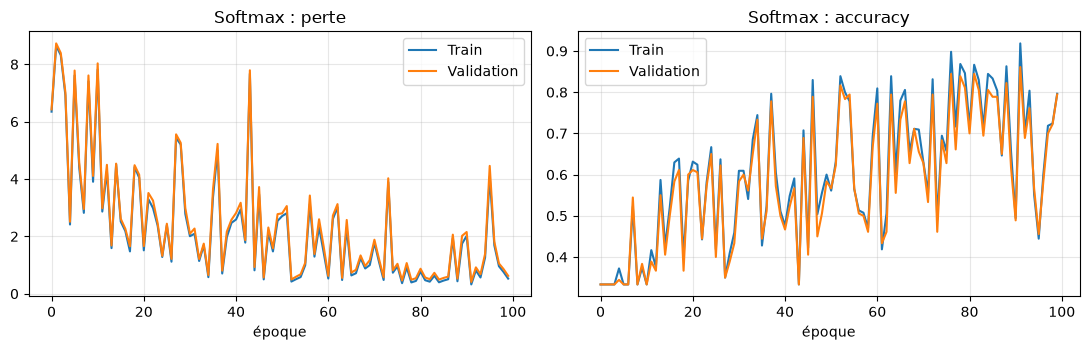

In [10]:
# 3.9 Entraînement final du Softmax avec la meilleure configuration, et courbes d'apprentissage
t0 = time.perf_counter()
softmax_final = SoftmaxClassifier(3072, N_CLASSES, lr=meilleur["lr"], reg=meilleur["reg"])
hist_sm = softmax_final.fit(X_train_flat.astype("float64"), y_train,
                            X_val_flat.astype("float64"), y_val, epochs=EPOCHS_SM)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
y_val_pred_sm = softmax_final.predict(X_val_flat.astype("float64"))
t_pred = time.perf_counter() - t0

val_scores["Softmax"] = summarize("Softmax", y_val, y_val_pred_sm)
timings["Softmax"] = {"fit_s": t_fit, "predict_s": t_pred}
print("Softmax | Validation :", val_scores["Softmax"])
print(f"Temps : fit {t_fit:.2f}s | prédiction {t_pred:.4f}s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hist_sm["loss"], label="Train"); axes[0].plot(hist_sm["val_loss"], label="Validation")
axes[0].set_title("Softmax : perte"); axes[0].set_xlabel("époque"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist_sm["acc"], label="Train"); axes[1].plot(hist_sm["val_acc"], label="Validation")
axes[1].set_title("Softmax : accuracy"); axes[1].set_xlabel("époque"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

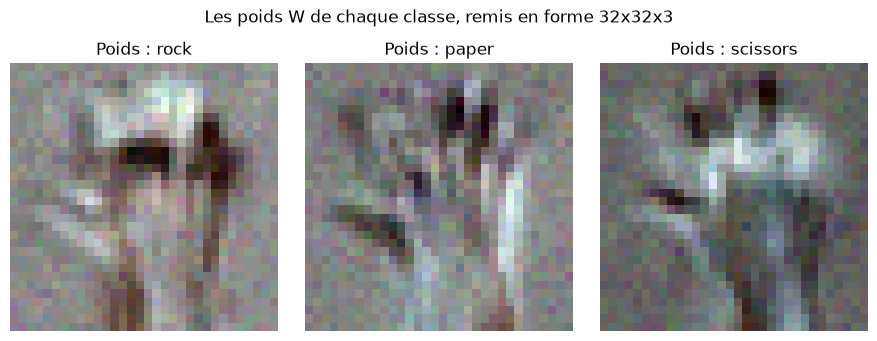

In [11]:
# 3.10 Que « voit » le classifieur ? On remet chaque colonne de W en image 32x32x3
W_img = softmax_final.W.T.reshape(N_CLASSES, 32, 32, 3)
fig, axes = plt.subplots(1, N_CLASSES, figsize=(9, 3.3))
for c in range(N_CLASSES):
    w = W_img[c]
    w = (w - w.min()) / (w.max() - w.min() + 1e-12)       # remise à l'échelle 0..1 pour l'affichage
    axes[c].imshow(w); axes[c].set_title(f"Poids : {class_names[c]}"); axes[c].axis("off")
plt.suptitle("Les poids W de chaque classe, remis en forme 32x32x3", y=1.02)
plt.tight_layout(); plt.show()

### 🔍 Interprétation Softmax
- Les **courbes** : la perte doit baisser. Si l'accuracy Train est bien supérieure à celle de la Validation, il y a **surapprentissage** (plus de régularisation peut aider).
- Les **images de poids** sont des sortes de « modèles moyens » de chaque geste : le classifieur linéaire apprend **un seul gabarit par classe**. C'est sa force (simple) et sa limite : il ne peut pas gérer les variations de position ou de forme.
- Rappel (Notebook 2) : le Softmax ne connaît pas le voisinage des pixels, il pèse chaque pixel séparément.

---
# Partie 4 : Le CNN (réseau de neurones convolutif)

## 4.1 Le concept
Le CNN reçoit l'image en `(32, 32, 3)` et apprend lui-même des **filtres** qui détectent des motifs locaux, de plus en plus complexes d'une couche à l'autre.

## 4.2 Les briques de notre architecture
| Couche | Rôle |
|---|---|
| `Conv2D(n, 3×3, ReLU)` | applique *n* filtres 3×3 appris ; **ReLU** met à 0 les valeurs négatives (ajoute de la non-linéarité) |
| `MaxPooling2D(2×2)` | garde le maximum de chaque bloc 2×2 : divise la taille par 2, rend le modèle moins sensible aux petits décalages |
| `Flatten` | aplatit les cartes pour les donner aux couches suivantes |
| `Dense(64, ReLU)` | couche entièrement connectée |
| `Dense(3, softmax)` | sortie : 3 probabilités (rock, paper, scissors) |

Évolution des formes : `32×32×3` → conv → pool `16×16` → conv → pool `8×8` → Flatten.

## 4.3 Entraînement
- **Perte** : `sparse_categorical_crossentropy` (nos labels sont des entiers, voir Notebook 2).
- **Optimiseur** : **Adam**, une descente de gradient améliorée qui adapte le pas automatiquement.
- **Batch size 32** : le gradient est calculé sur 32 images à la fois.
- **Époque** : un passage complet sur les 540 images d'entraînement.
- **EarlyStopping** : on surveille la perte sur la Validation et on **arrête** quand elle ne s'améliore plus pendant 8 époques ; on **restaure** les meilleurs poids. Cela évite le surapprentissage et choisit automatiquement le nombre d'époques.

In [41]:
# 4.4 Construction du CNN
def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(N_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

tf.keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 281,795 (1.07 MB)

 Trainable params: 281,795 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 4.5 Entraînement du CNN (Train) avec suivi sur la Validation
EPOCHS_CNN = 60
BATCH_SIZE = 32

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

t0 = time.perf_counter()
history = cnn.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=EPOCHS_CNN, batch_size=BATCH_SIZE,
                  callbacks=[early_stop], verbose=2)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
proba_val_cnn = cnn.predict(X_val, verbose=0)
t_pred = time.perf_counter() - t0
y_val_pred_cnn = np.argmax(proba_val_cnn, axis=1)

val_scores["CNN"] = summarize("CNN", y_val, y_val_pred_cnn)
timings["CNN"] = {"fit_s": t_fit, "predict_s": t_pred}
print("\nCNN | Validation :", val_scores["CNN"])
print(f"Époques effectuées : {len(history.history['loss'])} | temps fit {t_fit:.1f}s | prédiction {t_pred:.3f}s")

Epoch 1/60
17/17 - 3s - 194ms/step - accuracy: 0.3648 - loss: 1.0968 - val_accuracy: 0.4389 - val_loss: 1.0637
Epoch 2/60
17/17 - 0s - 24ms/step - accuracy: 0.6074 - loss: 0.9643 - val_accuracy: 0.8000 - val_loss: 0.7409
Epoch 3/60
17/17 - 0s - 24ms/step - accuracy: 0.7741 - loss: 0.5799 - val_accuracy: 0.8056 - val_loss: 0.4244
Epoch 4/60
17/17 - 0s - 26ms/step - accuracy: 0.8944 - loss: 0.3032 - val_accuracy: 0.9500 - val_loss: 0.1733
Epoch 5/60
17/17 - 0s - 24ms/step - accuracy: 0.9296 - loss: 0.1822 - val_accuracy: 0.9611 - val_loss: 0.1087
Epoch 6/60
17/17 - 0s - 24ms/step - accuracy: 0.9852 - loss: 0.0685 - val_accuracy: 0.9944 - val_loss: 0.0458
Epoch 7/60
17/17 - 0s - 26ms/step - accuracy: 0.9963 - loss: 0.0371 - val_accuracy: 1.0000 - val_loss: 0.0178
Epoch 8/60
17/17 - 0s - 24ms/step - accuracy: 0.9963 - loss: 0.0231 - val_accuracy: 0.9944 - val_loss: 0.0414
Epoch 9/60
17/17 - 0s - 26ms/step - accuracy: 0.9944 - loss: 0.0218 - val_accuracy: 1.0000 - val_loss: 0.0284
Epoch 10/

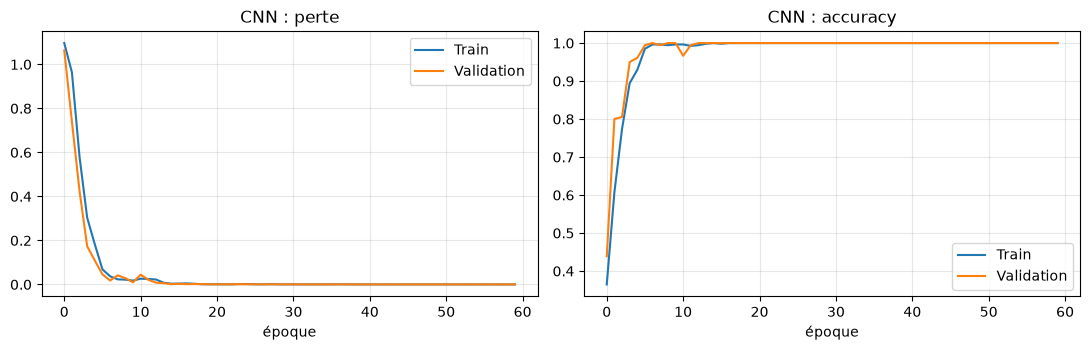

In [15]:
# 4.6 Courbes d'apprentissage du CNN (Train vs Validation)
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(h["loss"], label="Train"); axes[0].plot(h["val_loss"], label="Validation")
axes[0].set_title("CNN : perte"); axes[0].set_xlabel("époque"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(h["accuracy"], label="Train"); axes[1].plot(h["val_accuracy"], label="Validation")
axes[1].set_title("CNN : accuracy"); axes[1].set_xlabel("époque"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 🔍 Interprétation CNN
- Compare Train et Validation : un grand écart signale un **surapprentissage** (le modèle « apprend par cœur » les 540 images).
- Si nécessaire, on peut tester **sur la Validation** une augmentation de données (retournements, petites rotations), moins de filtres ou davantage de données (mais le projet impose 300 images/classe).
- Le nombre de paramètres du CNN est affiché dans `summary()` : **voir summary()** pour la valeur correspondant à l'architecture utilisée.

> 📝 **Comparaison sur la Validation** (le Test n'a toujours pas été utilisé) : c'est la cellule suivante.

In [16]:
# 4.7 Comparaison provisoire sur la VALIDATION (pas encore le Test !)
print(f"{'Modèle':10s}{'accuracy':>10s}{'F1 macro':>10s}")
for nom, sc in val_scores.items():
    print(f"{nom:10s}{sc['accuracy']:10.3f}{sc['f1_macro']:10.3f}")

Modèle      accuracy  F1 macro
k-NN           1.000     1.000
Softmax        0.794     0.795
CNN            1.000     1.000


---
# Partie 5 : Évaluation finale sur le Test et comparaison

⚠️ **C'est ici — et seulement ici — que l'on utilise le Test.** On ne modifie plus aucun modèle ni hyperparamètre après cette étape. Si les résultats déçoivent, on **ne retourne pas** régler les modèles en regardant le Test : on analyse et on le documente dans le rapport.

In [17]:
# 5.1 Prédictions sur le Test avec les trois modèles finaux
preds_test["k-NN"] = knn_final.predict(X_test_flat)
preds_test["Softmax"] = softmax_final.predict(X_test_flat.astype("float64"))
preds_test["CNN"] = np.argmax(cnn.predict(X_test, verbose=0), axis=1)

for nom, yp in preds_test.items():
    results[nom] = summarize(nom, y_test, yp)

print(f"{'Modèle':10s}{'accuracy':>10s}{'F1 macro':>10s}{'fit (s)':>10s}{'prédiction (s)':>16s}")
for nom in ["k-NN", "Softmax", "CNN"]:
    r, t = results[nom], timings[nom]
    print(f"{nom:10s}{r['accuracy']:10.3f}{r['f1_macro']:10.3f}{t['fit_s']:10.2f}{t['predict_s']:16.4f}")

Modèle      accuracy  F1 macro   fit (s)  prédiction (s)
k-NN           0.972     0.972      0.00          0.2498
Softmax        0.783     0.774      1.14          0.0019
CNN            1.000     1.000     29.01          0.3809


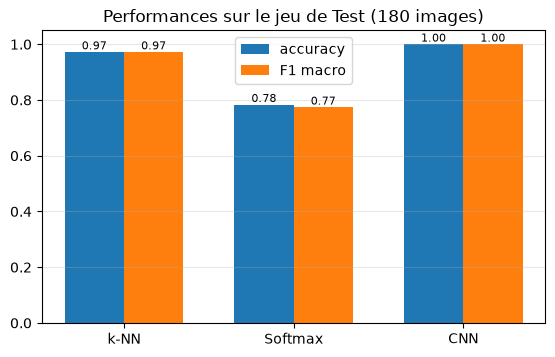

In [18]:
# 5.2 Diagramme en barres : accuracy et F1 macro sur le Test
noms = ["k-NN", "Softmax", "CNN"]
x = np.arange(len(noms)); w = 0.35
fig, ax = plt.subplots(figsize=(6.5, 3.8))
b1 = ax.bar(x - w / 2, [results[n]["accuracy"] for n in noms], w, label="accuracy")
b2 = ax.bar(x + w / 2, [results[n]["f1_macro"] for n in noms], w, label="F1 macro")
ax.set_xticks(x); ax.set_xticklabels(noms); ax.set_ylim(0, 1.05)
ax.set_title("Performances sur le jeu de Test (180 images)")
ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.show()

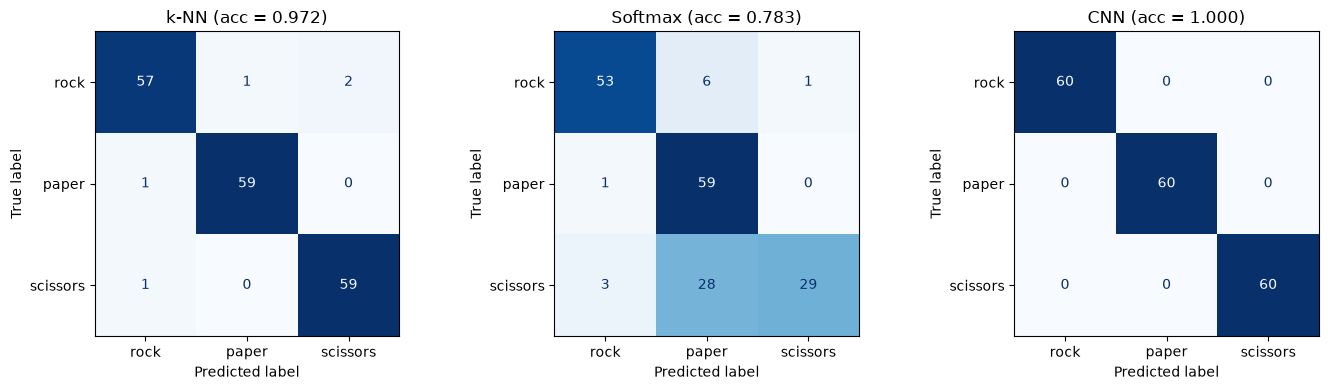

Rapport détaillé du CNN (précision / rappel / F1 par classe) :
              precision    recall  f1-score   support

        rock      1.000     1.000     1.000        60
       paper      1.000     1.000     1.000        60
    scissors      1.000     1.000     1.000        60

    accuracy                          1.000       180
   macro avg      1.000     1.000     1.000       180
weighted avg      1.000     1.000     1.000       180



In [19]:
# 5.3 Matrices de confusion sur le Test
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, nom in zip(axes, noms):
    show_confusion(y_test, preds_test[nom], f"{nom} (acc = {results[nom]['accuracy']:.3f})", ax=ax)
plt.tight_layout(); plt.show()

print("Rapport détaillé du CNN (précision / rappel / F1 par classe) :")
print(classification_report(y_test, preds_test["CNN"], target_names=class_names, digits=3, zero_division=0))

In [20]:
# 5.4 Sauvegarde des résultats ET des trois modèles (utilisés ensuite par la plateforme web)
import joblib
os.makedirs("models", exist_ok=True)

resume_final = {nom: {**results[nom], **timings[nom]} for nom in noms}
resume_final["_config"] = {"SEED": SEED, "knn": best, "softmax": meilleur,
                           "cnn_epochs_effectuees": len(history.history["loss"])}
resume_final["_class_names"] = class_names
with open("models/resultats_modeles.json", "w", encoding="utf-8") as f:
    json.dump(resume_final, f, indent=2, ensure_ascii=False, default=str)

joblib.dump(knn_final, "models/knn.joblib")                                   # k-NN (contient les 540 images mémorisées)
np.savez("models/softmax.npz", W=softmax_final.W, b=softmax_final.b)          # poids du classifieur Softmax
cnn.save("models/cnn_rps.keras")                                              # CNN entraîné

print("Dossier 'models/' prêt :", sorted(os.listdir("models")))

Dossier 'models/' prêt : ['cnn_rps.keras', 'knn.joblib', 'resultats_modeles.json', 'softmax.npz']


---
# Partie 6 : Analyse des erreurs et pistes pour le rapport

In [21]:
# 6.1 Quelles images le meilleur modèle se trompe-t-il à classer ?
meilleur_nom = max(noms, key=lambda n: results[n]["accuracy"])
yp = preds_test[meilleur_nom]
erreurs_idx = np.where(yp != y_test)[0]
print(f"Meilleur modèle sur le Test : {meilleur_nom} ({len(erreurs_idx)} erreurs sur {len(y_test)})")

n_show = min(10, len(erreurs_idx))
if n_show > 0:
    fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), erreurs_idx[:n_show]):
        ax.imshow(X_test[i])
        ax.set_title(f"vrai : {class_names[y_test[i]]}\nprédit : {class_names[yp[i]]}", fontsize=9, color="crimson")
    plt.suptitle(f"Erreurs de {meilleur_nom} sur le Test", y=1.0)
    plt.tight_layout(); plt.show()
else:
    print("Aucune erreur : excellent résultat (à vérifier qu'il n'y a pas de fuite de données).")

Meilleur modèle sur le Test : CNN (0 erreurs sur 180)
Aucune erreur : excellent résultat (à vérifier qu'il n'y a pas de fuite de données).


## 6.2 Pistes de discussion pour le rapport

**Comparaison des performances**
- Quel modèle a la meilleure accuracy et le meilleur F1 sur le Test ? L'écart est-il grand ? Avec 180 images de test, une différence de 1 à 2 points correspond à 2 ou 3 images : sois prudent avant de conclure.
- Quelles classes sont confondues ? Les confusions sont-elles les mêmes pour les trois modèles ?

**Interprétation des résultats**
- k-NN : compare des pixels ; sensible à la position de la main, au fond, à l'éclairage.
- Softmax : un gabarit linéaire par classe (voir les images de poids) ; limité pour les variations de forme.
- CNN : filtres locaux appris, partage de poids, robustesse aux petits décalages grâce au pooling.

**Coût**
- Compare les temps d'entraînement et de prédiction. k-NN s'entraîne instantanément mais prédit lentement ; le CNN est plus long à entraîner.

**Limites de l'étude** (à mentionner honnêtement)
- Petit jeu de données (900 images) et résolution faible (32×32).
- Un seul découpage Train/Validation/Test : les résultats peuvent varier avec une autre graine. Pour renforcer la conclusion, on pourrait répéter l'expérience avec plusieurs graines et donner moyenne ± écart-type.
- Les images de ce dataset sont synthétiques (mains générées sur fond uni) : les performances peuvent être meilleures que sur des photos réelles.

**Pistes d'amélioration** (hors consignes, pour la discussion)
- Augmentation de données pour le CNN, validation croisée pour k-NN et Softmax, tests d'autres architectures.

---
🎉 **Fin du Notebook 3.** Tu disposes de trois modèles entraînés dans des conditions identiques, d'une évaluation honnête sur le Test et de résultats sauvegardés pour ton rapport.